# 01 · Exploratory data analysis

Targets: **`final_result`** (4-class: Withdrawn / Fail / Pass / Distinction) and **`final_coursework_score`** (regression).

The figures are produced by `oauld.eda.run()` (also available as `make eda`) and stored in `reports/figures/eda/`; this notebook shows the summary tables and the key figures.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, display
from oauld import config as C, eda
from oauld.data import load_raw

train, test, private = load_raw()
print(train.shape, test.shape, private.shape)
tables = eda.attribute_tables(train)

(18802, 43) (4700, 43) (4700, 42)


## Attribute types
- **Numeric (continuous / count)** – all remaining columns (clicks, scores, dates…)
- **Nominal** – `code_module`, `code_presentation`, `gender`, `region`, `disability`
- **Ordinal** – `highest_education`, `imd_band`, `age_band`, `clicks_freq_init`

In [2]:
tables['numeric']

,count,mean,std,min,25%,50%,75%,max
num_of_prev_attempts,18802.0,0.17,0.48,0.00,0.00,0.00,0.00,6.00
studied_credits,18802.0,80.44,37.06,30.00,60.00,60.00,120.00,430.00
date_registration,18799.0,-67.87,47.85,-311.00,-98.00,-54.00,-29.00,167.00
date_unregistration,3542.0,111.39,62.19,-196.00,59.00,108.00,159.00,444.00
module_presentation_length,18802.0,256.03,13.33,234.00,241.00,262.00,268.00,269.00
n_assessments_early,18787.0,2.66,1.15,1.00,2.00,2.00,3.00,6.00
mean_score_early,18770.0,74.36,17.16,0.00,66.50,78.33,86.67,100.00
weighted_mean_score_early,18780.0,73.43,16.57,0.00,64.70,76.00,85.62,100.00
total_clicks_early,18802.0,791.46,860.59,0.00,262.00,523.00,1004.75,12783.00
active_days_early,18802.0,35.61,22.45,0.00,18.00,31.00,49.00,115.00


In [3]:
tables['nominal']

,non_null,unique,most_frequent,missing
code_module,18802,6,FFF,0
code_presentation,18802,4,2014J,0
gender,18802,2,M,0
region,18802,13,Scotland,0
disability,18802,2,N,0


In [4]:
tables['ordinal']

,non_null,unique,most_frequent,missing
highest_education,18802,5,A Level or Equivalent,0
imd_band,18028,10,30-40%,774
age_band,18802,3,0-35,0
clicks_freq_init,18742,3,high,60


## Figures

In [5]:
eda.run()   # regenerates every figure and prints the two statistical tests

Kruskal-Wallis mean_score_early ~ final_result: H=4633.0, p=0.00e+00
Chi-square highest_education ~ final_result: chi2=665.1, dof=12, p=1.32e-134


EDA figures written to /home/sebastian/Desktop/Stuff/UNI/IA/Tema1/reports/figures/eda


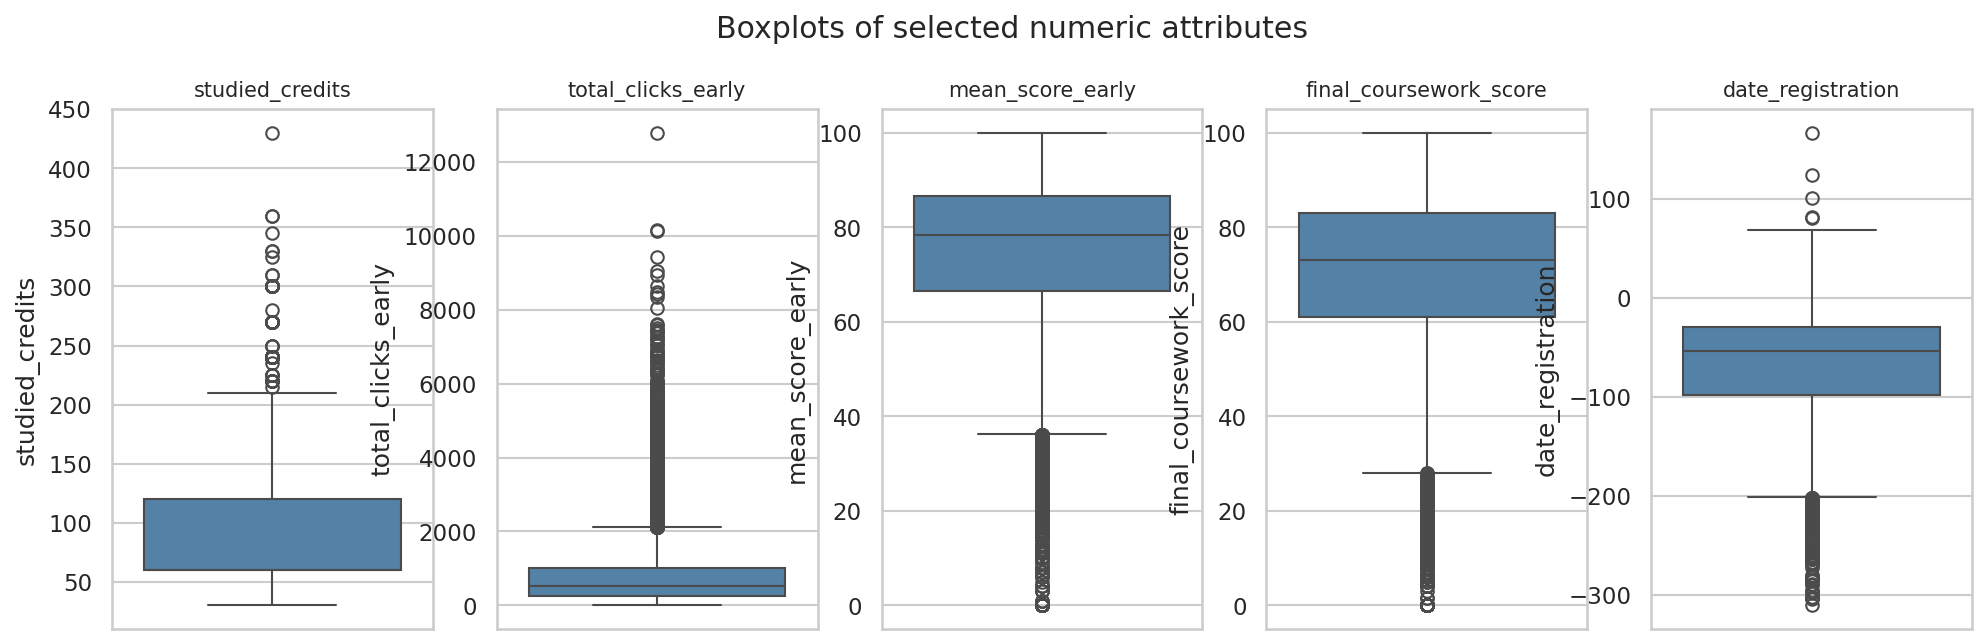

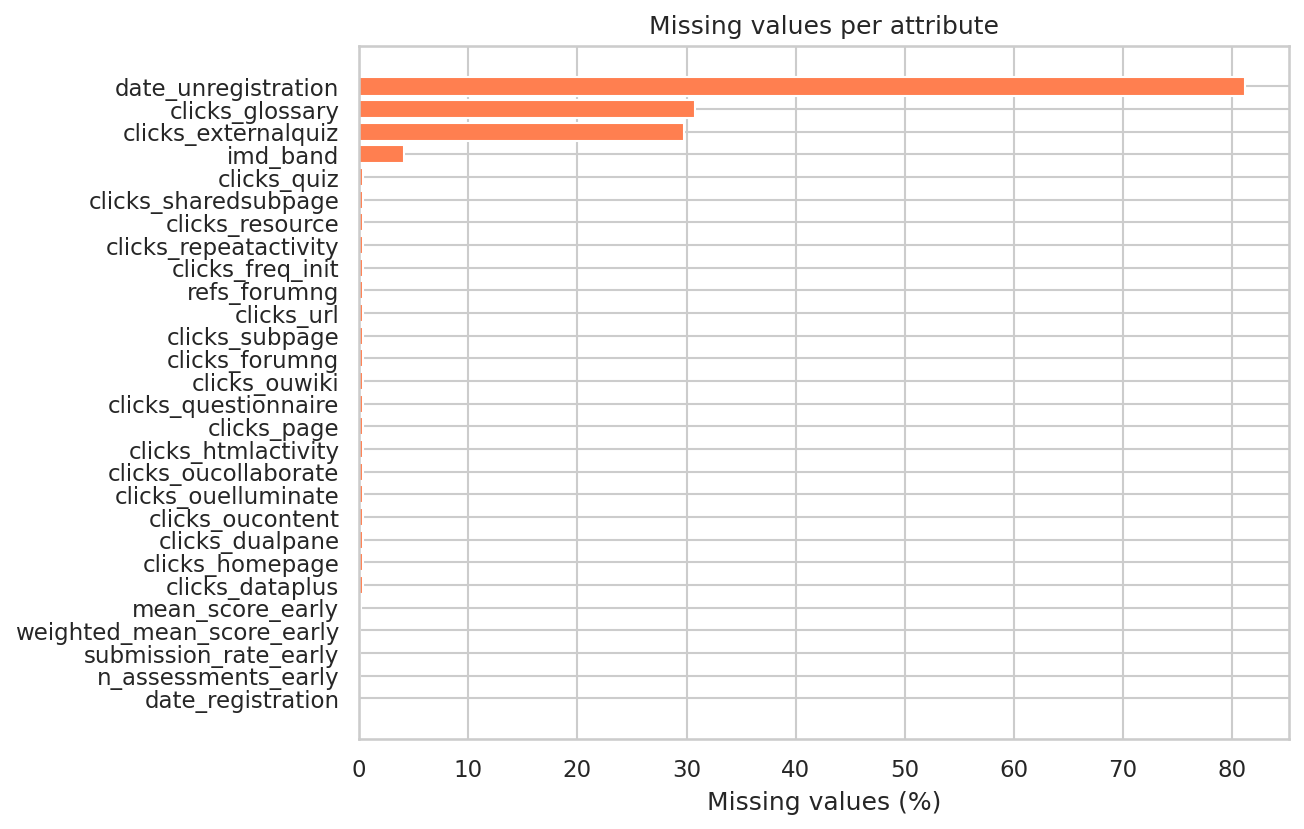

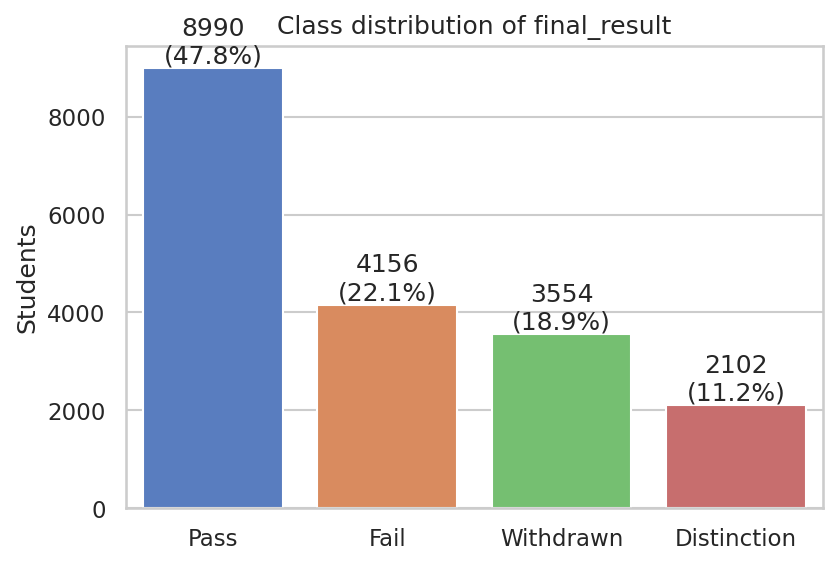

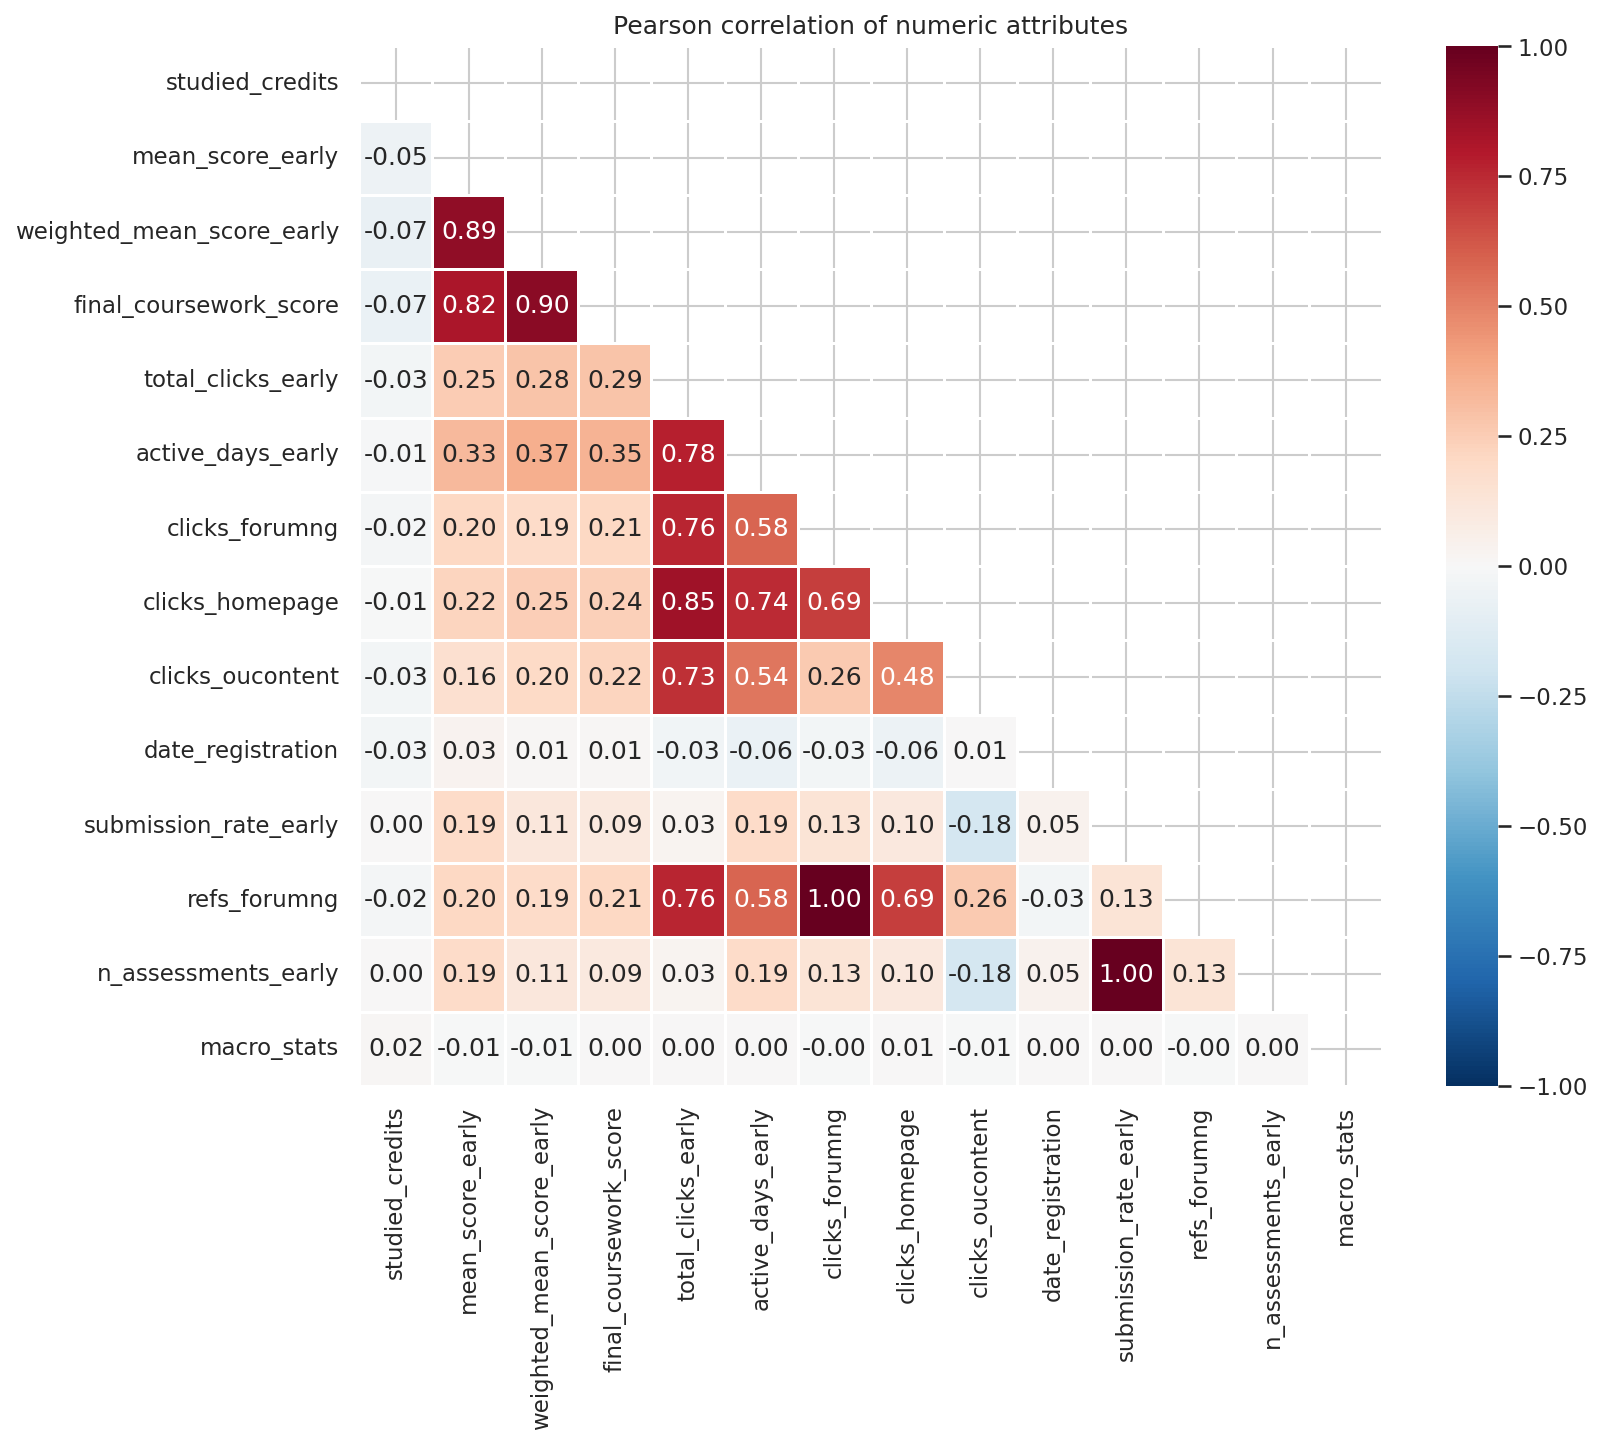

In [6]:
for f in ['01_boxplot_numeric','03_missing_values','04_class_balance','05_correlation_heatmap']:
    display(Image(str(eda.EDA_DIR / f'{f}.png')))

**Take-aways**
- `date_unregistration` is missing for ~81 % of students; when present, 99.6 % of them are *Withdrawn* – the strongest single signal for that class, so the pipeline keeps it as an explicit `was_unregistered` flag.
- `clicks_*` gaps mean *no activity* and are filled with 0.
- Classes are imbalanced (Pass 48 %, Fail 22 %, Withdrawn 19 %, Distinction 11 %): accuracy alone is misleading, so macro-F1 is the selection metric.
- `mean_score_early` ≈ `weighted_mean_score_early` (r = 0.97) and `clicks_forumng` ≈ `refs_forumng` (r = 0.99) are redundant; removing them did not help the models, so they are kept.
- `mean_score_early` is the best single predictor of both targets (Pearson r ≈ 0.8 with the final score; Kruskal-Wallis p < 1e-300 across classes).

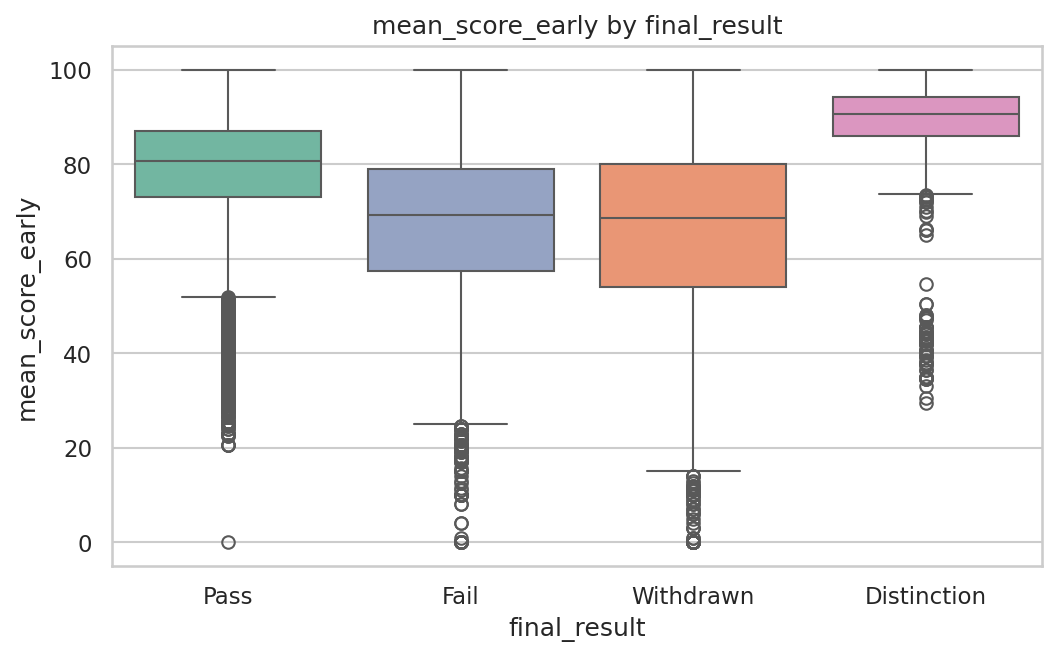

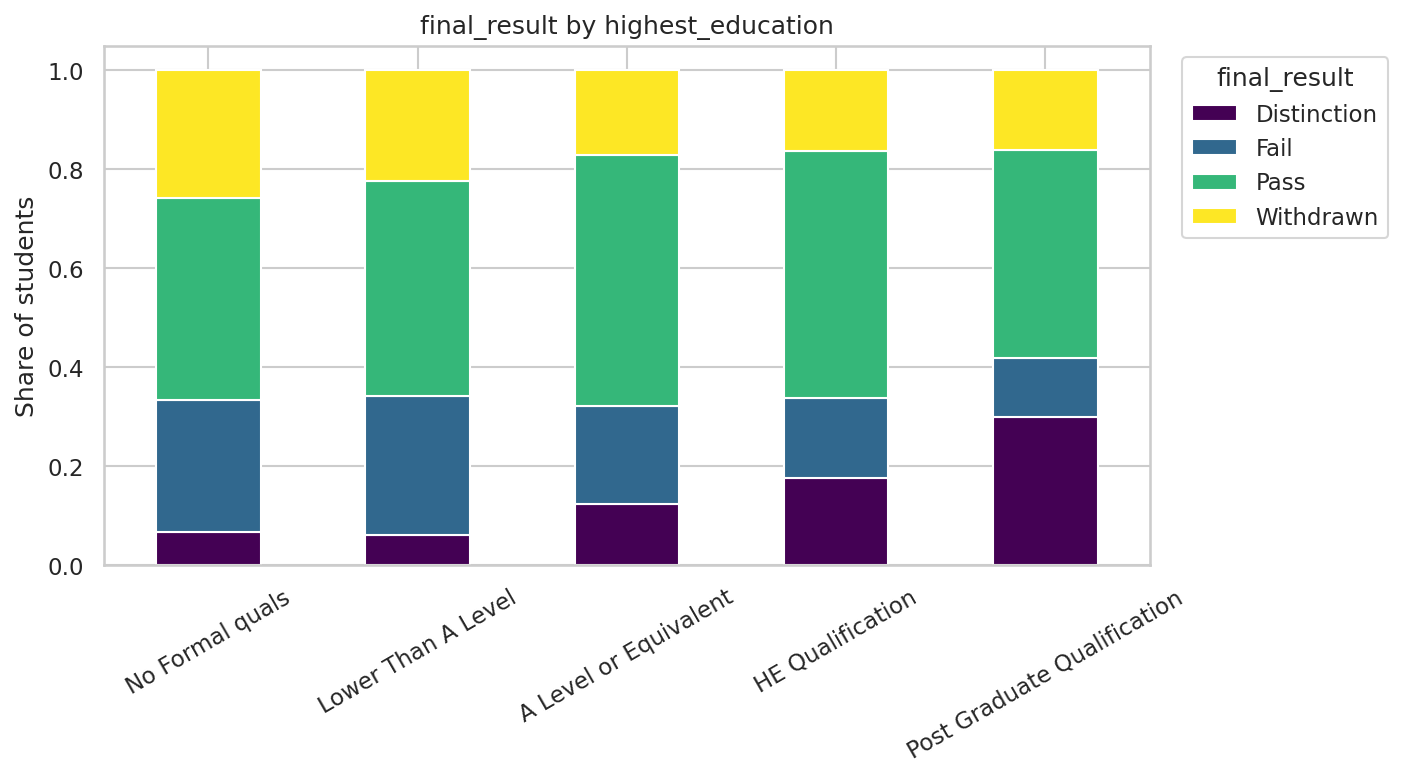

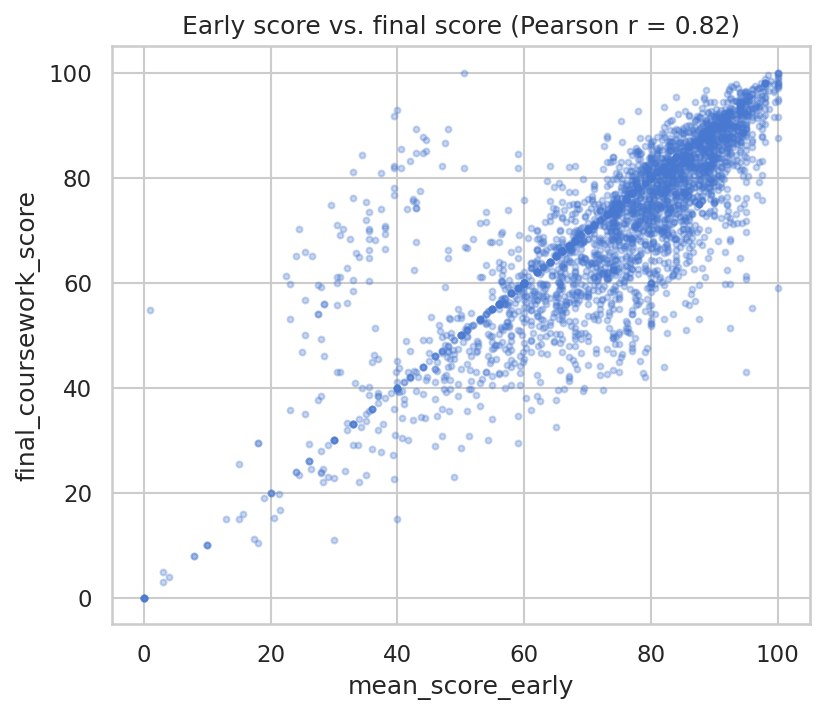

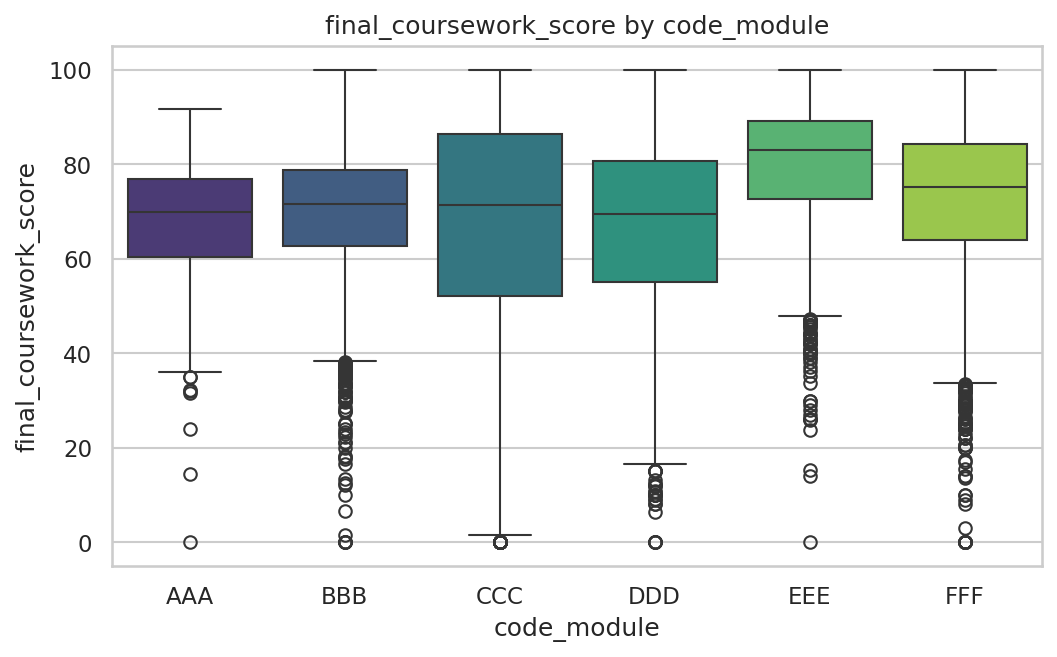

In [7]:
for f in ['06_numeric_vs_classification','07_categorical_vs_classification','08_numeric_vs_regression','09_categorical_vs_regression']:
    display(Image(str(eda.EDA_DIR / f'{f}.png')))